In [ ]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import display
import pandas as pd
import zipfile
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/DLproj')
LOCAL_DATA = Path('/content/dataset')
ZIP_PATH = DRIVE_ROOT / 'SUIM_new.zip'

if ZIP_PATH.is_file():
    print(f'Found {ZIP_PATH.name} at {DRIVE_ROOT}. Extracting to {LOCAL_DATA} for fast I/O...')
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_DATA)
    print('Extraction complete!')
else:
    print(f'Error: Could not find {ZIP_PATH.name} in {DRIVE_ROOT}. Please verify the file exists.')

DATA_ROOT = LOCAL_DATA if LOCAL_DATA.is_dir() else DRIVE_ROOT

TRAIN_DIR = DATA_ROOT / 'SUIM_new' / 'train_val'
if not TRAIN_DIR.is_dir():
    TRAIN_DIR = DATA_ROOT / 'train_val'

TEST_DIR = DATA_ROOT / 'SUIM_new' / 'TEST'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found SUIM_new.zip at /content/drive/MyDrive/DLproj. Extracting to /content/dataset for fast I/O...
Extraction complete!


In [ ]:
IMG_HEIGHT, IMG_WIDTH = 256, 256
BATCH_SIZE = 8
EPOCHS = 150
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x
def build_mobilenet_unet(input_shape=(256, 256, 3), num_classes=5):
    base = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')
    skip_names = ['block_1_expand_relu', 'block_3_expand_relu', 'block_6_expand_relu',
                  'block_13_expand_relu', 'block_16_project']
    encoder = models.Model(base.input, [base.get_layer(n).output for n in skip_names])

    inputs = layers.Input(shape=input_shape)
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)   # your [0,1] -> [-1,1] for MobileNetV2
    f1, f2, f3, f4, f5 = encoder(x)                  # 128, 64, 32, 16, 8

    d = f5
    for skip, filters in [(f4, 256), (f3, 128), (f2, 64), (f1, 32)]:
        d = layers.UpSampling2D(interpolation='bilinear')(d)
        d = layers.concatenate([d, skip])
        d = conv_block(d, filters)
    d = layers.UpSampling2D(interpolation='bilinear')(d)   # back to 256x256
    d = conv_block(d, 16)
    outputs = layers.Conv2D(num_classes, 1, activation='sigmoid')(d)
    return models.Model(inputs, outputs)


def soft_dice_per_class(y_true, y_pred, smooth=1.0):
    y_true = tf.cast(y_true, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred, axis=[0, 1, 2])
    denom = tf.reduce_sum(y_true, axis=[0, 1, 2]) + tf.reduce_sum(y_pred, axis=[0, 1, 2])
    return (2.0 * inter + smooth) / (denom + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - tf.reduce_mean(soft_dice_per_class(y_true, y_pred)))

def mean_dice(y_true, y_pred):
    return tf.reduce_mean(soft_dice_per_class(y_true, y_pred))

model = build_mobilenet_unet(num_classes=len(CLASSES))

model.compile(optimizer=tf.keras.optimizers.Adam(3e-4),
              loss=bce_dice_loss, metrics=[mean_dice])
model.summary()

/tmp/ipykernel_2319/3643668287.py:14: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 256, 256,  │          0 │ input_layer_11[0… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_10       │ [(None, 128, 128, │  1,841,984 │ rescaling_1[0][0] │
│ (Functional)        │ 96), (None, 64,   │            │                   │
│                     │ 64, 144), (None,  │            │                   │
│                     │ 32, 32, 192),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 576), (None, 8,   │            │                   │
│                     │ 8, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_5     │ (None, 16, 16,    │          0 │ functional_10[0]… │
│ (UpSampling2D)      │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_24      │ (None, 16, 16,    │          0 │ up_sampling2d_5[… │
│ (Concatenate)       │ 896)              │            │ functional_10[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_85 (Conv2D)  │ (None, 16, 16,    │  2,064,384 │ concatenate_24[0… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_85[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_46       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_86 (Conv2D)  │ (None, 16, 16,    │    589,824 │ activation_46[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_86[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_47       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 32, 32,    │          0 │ activation_47[0]… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_25      │ (None, 32, 32,    │          0 │ up_sampling2d_6[… │
│ (Concatenate)       │ 448)              │            │ functional_10[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_87 (Conv2D)  │ (None, 32, 32,    │    516,096 │ concatenate_25[0… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_87[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                 

 Total params: 5,419,541 (20.67 MB)

 Trainable params: 5,386,645 (20.55 MB)

 Non-trainable params: 32,896 (128.50 KB)

In [ ]:
import glob

def load_dataset(images_dir, masks_dir, size):
    image_paths = sorted(glob.glob(str(images_dir / 'images' / '*.*')))
    xs, ys = [], []

    # Colors for SUIM 5 classes
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])

    for img_path in image_paths:
        stem = Path(img_path).stem
        mask_path = masks_dir / f'{stem}.bmp'
        if not mask_path.exists():
            mask_path = masks_dir / f'{stem}.png'
        if not mask_path.exists():
            continue

        img = Image.open(img_path).convert('RGB').resize((size[1], size[0]), Image.Resampling.BILINEAR)
        mask = Image.open(mask_path).convert('RGB').resize((size[1], size[0]), Image.Resampling.NEAREST)

        img_arr = np.asarray(img, dtype=np.float32) / 255.0
        mask_arr = np.asarray(mask, dtype=np.float32)

        target = np.all(mask_arr[..., None, :] == (colors * 255), axis=-1).astype(np.float32)

        xs.append(img_arr)
        ys.append(target)

    return np.array(xs), np.array(ys)

print("Loading training data into memory...")
X_train, Y_train = load_dataset(TRAIN_DIR, TRAIN_DIR / 'masks', (IMG_HEIGHT, IMG_WIDTH))
print(f"Loaded {len(X_train)} training samples.")
# ---------- Augmentation ----------
H, W = IMG_HEIGHT, IMG_WIDTH
N_CLS = len(Y_train[0][0][0])  # 5 classes

def augment(img, mask):
    both = tf.concat([img, mask], axis=-1)
    both = tf.image.random_flip_left_right(both)
    img, mask = both[..., :3], both[..., 3:]

    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return tf.clip_by_value(img, 0.0, 1.0), mask

# ---------- Train / val split (val is NOT augmented) ----------
rng = np.random.RandomState(42)
idx = rng.permutation(len(X_train))
n_val = int(0.2 * len(idx))
val_idx, train_idx = idx[:n_val], idx[n_val:]

sig = (tf.TensorSpec((H, W, 3), tf.float32), tf.TensorSpec((H, W, N_CLS), tf.float32))

def make_gen(indices):
    def gen():
        for i in indices:
            yield X_train[i], Y_train[i]
    return gen

train_ds = (tf.data.Dataset.from_generator(make_gen(train_idx), output_signature=sig)
            .shuffle(256)
            .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (tf.data.Dataset.from_generator(make_gen(val_idx), output_signature=sig)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_mean_dice', mode='max', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_mean_dice', mode='max', patience=15, restore_best_weights=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Loading training data into memory...
Loaded 1525 training samples.
Epoch 1/150
    153/Unknown 142s 373ms/step - loss: 1.3263 - mean_dice: 0.1877

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


153/153 ━━━━━━━━━━━━━━━━━━━━ 159s 490ms/step - loss: 1.2464 - mean_dice: 0.2094 - val_loss: 1.2038 - val_mean_dice: 0.2390 - learning_rate: 3.0000e-04
Epoch 2/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 1.0687 - mean_dice: 0.2590 - val_loss: 1.1006 - val_mean_dice: 0.2324 - learning_rate: 3.0000e-04
Epoch 3/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.9681 - mean_dice: 0.2913 - val_loss: 0.9926 - val_mean_dice: 0.2560 - learning_rate: 3.0000e-04
Epoch 4/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 0.8794 - mean_dice: 0.3296 - val_loss: 0.9337 - val_mean_dice: 0.3089 - learning_rate: 3.0000e-04
Epoch 5/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.7967 - mean_dice: 0.3751 - val_loss: 0.9390 - val_mean_dice: 0.2949 - learning_rate: 3.0000e-04
Epoch 6/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.7515 - mean_dice: 0.4034 - val_loss: 0.9276 - val_mean_dice: 0.3081 - learning_rate: 3.0000e-04
Epoch 7/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/

Evaluating sample stem: w_r_30_
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


,Class Name,F1 (Dice),IoU
0,Robots,1.000000,1.000000
1,Fish and Vertebrates,0.952047,0.908483
2,Human Divers,1.000000,1.000000
3,Reefs and Invertebrates,0.000000,0.000000
4,Wrecks and Ruins,0.189319,0.104557


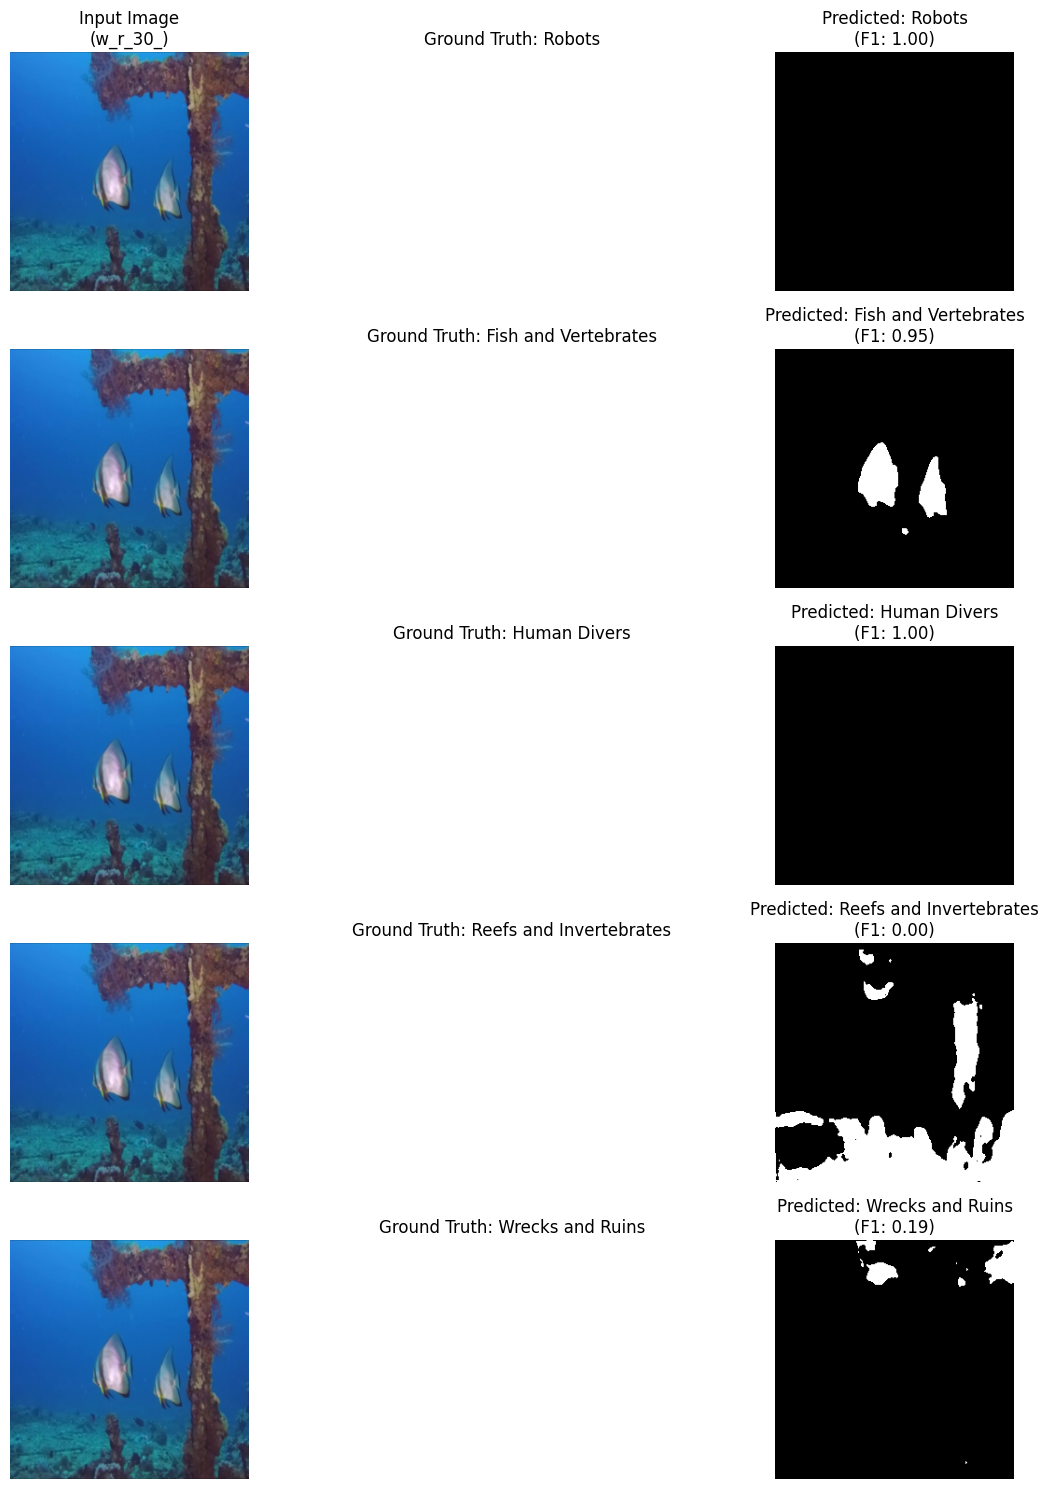

In [ ]:
import matplotlib.pyplot as plt
import glob
import random
import numpy as np
import pandas as pd
from pathlib import Path

CLASS_MAP = {
    'Robots': 'RO',
    'Fish and Vertebrates': 'FV',
    'Human Divers': 'HD',
    'Reefs and Invertebrates': 'RI',
    'Wrecks and Ruins': 'WR'
}
CLASSES = list(CLASS_MAP.keys())

def calculate_metrics(y_true, y_pred):
    intersection = np.logical_and(y_true, y_pred).sum()
    union = np.logical_or(y_true, y_pred).sum()

    # IoU
    iou = intersection / union if union > 0 else 1.0

    # F1 / Dice Score
    dice = (2.0 * intersection) / (y_true.sum() + y_pred.sum()) if (y_true.sum() + y_pred.sum()) > 0 else 1.0
    return dice, iou

test_image_paths = sorted(glob.glob(str(TEST_DIR / 'images' / '*.*')))
if not test_image_paths:
    raise ValueError(f"No test images found in {TEST_DIR / 'images'}")

sample_img_path = random.choice(test_image_paths)
stem = Path(sample_img_path).stem
print(f"Evaluating sample stem: {stem}")

original_image = Image.open(sample_img_path).convert('RGB')
img_resized = original_image.resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.BILINEAR)
input_tensor = np.expand_dims(np.asarray(img_resized, dtype=np.float32) / 255.0, axis=0)

raw_pred = model.predict(input_tensor)[0] # Shape
pred_mask = (raw_pred > 0.5).astype(np.uint8) # Threshold

gt_mask_full = np.zeros((IMG_HEIGHT, IMG_WIDTH, len(CLASSES)), dtype=np.float32)

for idx, cls_name in enumerate(CLASSES):
    symbol = CLASS_MAP[cls_name]
    gt_class_path = TEST_DIR / 'masks' / symbol / f'{stem}.bmp'
    if not gt_class_path.exists():
        gt_class_path = TEST_DIR / 'masks' / symbol / f'{stem}.png'

    if gt_class_path.exists():
        gt_img = Image.open(gt_class_path).convert('L').resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.NEAREST)
        gt_mask_full[..., idx] = (np.asarray(gt_img, dtype=np.float32) / 255.0) >= 0.5

evaluation_results = []
for idx, cls_name in enumerate(CLASSES):
    y_true = gt_mask_full[..., idx]
    y_pred = pred_mask[..., idx]
    f1, iou = calculate_metrics(y_true, y_pred)
    evaluation_results.append({'Class Name': cls_name, 'F1 (Dice)': f1, 'IoU': iou})

eval_df = pd.DataFrame(evaluation_results)
display(eval_df)

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 3 * len(CLASSES)))
if len(CLASSES) == 1:
    axes = np.expand_dims(axes, 0)

for idx, cls_name in enumerate(CLASSES):
    axes[idx, 0].imshow(img_resized)
    axes[idx, 0].set_title(f"Input Image\n({stem})" if idx == 0 else "")
    axes[idx, 0].axis('off')

    axes[idx, 1].set_title(f"Ground Truth: {cls_name}")
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(pred_mask[..., idx], cmap='gray', vmin=0, vmax=1)
    axes[idx, 2].set_title(f"Predicted: {cls_name}\n(F1: {evaluation_results[idx]['F1 (Dice)']:.2f})")
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import glob

CLASS_MAP = {
    'Robots': 'RO',
    'Fish and Vertebrates': 'FV',
    'Human Divers': 'HD',
    'Reefs and Invertebrates': 'RI',
    'Wrecks and Ruins': 'WR'
}

def evaluate_full_test_set(model, test_dir, class_map, img_height, img_width, threshold=0.5):
    test_image_paths = sorted(glob.glob(str(test_dir / 'images' / '*.*')))
    if not test_image_paths:
        raise ValueError(f"No test images found in {test_dir / 'images'}")

    class_metrics = {cls_name: {'f1_list': [], 'iou_list': []} for cls_name in class_map.keys()}

    print(f"Evaluating {len(test_image_paths)} test images across all classes...")
    for img_path in test_image_paths:
        stem = Path(img_path).stem

        img = Image.open(img_path).convert('RGB').resize((img_width, img_height), Image.Resampling.BILINEAR)
        input_tensor = np.expand_dims(np.asarray(img, dtype=np.float32) / 255.0, axis=0)

        raw_pred = model.predict(input_tensor, verbose=0)[0]
        pred_mask = (raw_pred > threshold).astype(np.uint8)

        for idx, (cls_name, symbol) in enumerate(class_map.items()):
            gt_path = test_dir / 'masks' / symbol / f'{stem}.bmp'
            if not gt_path.exists():
                gt_path = test_dir / 'masks' / symbol / f'{stem}.png'

            if gt_path.exists():
                gt_img = Image.open(gt_path).convert('L').resize((img_width, img_height), Image.Resampling.NEAREST)
                gt_mask = (np.asarray(gt_img, dtype=np.float32) / 255.0) >= 0.5
            else:
                gt_mask = np.zeros((img_height, img_width), dtype=bool)

            y_true = gt_mask.astype(bool)
            y_pred = pred_mask[..., idx].astype(bool)

            if y_true.sum() == 0 and y_pred.sum() == 0:
                continue

            intersection = np.logical_and(y_true, y_pred).sum()
            union = np.logical_or(y_true, y_pred).sum()

            iou = intersection / union if union > 0 else 0.0
            dice = (2.0 * intersection) / (y_true.sum() + y_pred.sum()) if (y_true.sum() + y_pred.sum()) > 0 else 0.0

            class_metrics[cls_name]['f1_list'].append(dice)
            class_metrics[cls_name]['iou_list'].append(iou)

    summary_rows = []
    macro_f1_vals = []
    macro_iou_vals = []

    for cls_name in class_map.keys():
        f1s = class_metrics[cls_name]['f1_list']
        ious = class_metrics[cls_name]['iou_list']

        mean_f1 = np.mean(f1s) if f1s else 0.0
        mean_iou = np.mean(ious) if ious else 0.0

        macro_f1_vals.append(mean_f1)
        macro_iou_vals.append(mean_iou)

        summary_rows.append({
            'Class Name': cls_name,
            'Scored Images': len(f1s),
            'F1 (Dice) %': round(mean_f1 * 100, 2),
            'IoU %': round(mean_iou * 100, 2)
        })

    summary_df = pd.DataFrame(summary_rows)
    overall_macro_f1 = np.mean(macro_f1_vals) * 100
    overall_macro_iou = np.mean(macro_iou_vals) * 100

    return summary_df, overall_macro_f1, overall_macro_iou

metrics_df, macro_f1, macro_iou = evaluate_full_test_set(
    model, TEST_DIR, CLASS_MAP, IMG_HEIGHT, IMG_WIDTH
)

print("\n" + "="*40)
print(f" FINAL MACRO F1 SCORE:  {macro_f1:.2f}%")
print(f" FINAL MACRO IoU SCORE: {macro_iou:.2f}%")
print("="*40 + "\n")

display(metrics_df)

Evaluating 110 test images across all classes...

 FINAL MACRO F1 SCORE:  58.47%
 FINAL MACRO IoU SCORE: 52.12%



,Class Name,Scored Images,F1 (Dice) %,IoU %
0,Robots,12,56.22,48.41
1,Fish and Vertebrates,76,63.38,55.43
2,Human Divers,45,72.04,66.17
3,Reefs and Invertebrates,78,54.45,48.57
4,Wrecks and Ruins,38,46.23,42.03
